# Switching Costs

This notebook visualizes the switching/resharding cost data already in the repo. The first plot shows the K-bar values used by the carbon-savings experiment runs. The second plot shows the measured resharding benchmark table, grouped by source and target configuration.

In [5]:
from __future__ import annotations

import csv
from collections import defaultdict
from pathlib import Path
from statistics import mean, stdev

import matplotlib.pyplot as plt
import numpy as np

try:
    import pandas as pd
except ImportError:
    pd = None

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "runs").exists():
    REPO_ROOT = REPO_ROOT.parent

def sample_std(values):
    return stdev(values) if len(values) > 1 else 0.0

def cfg_label(config):
    fields = {part[:2].upper(): part[2:] for part in config.split("_")}
    return f"DP{fields['DP']} TP{fields['TP']} PP{fields['PP']}"

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "-",
})

In [6]:
reshard_csv = REPO_ROOT / "results" / "resharding" / "reshard_times.csv"
with reshard_csv.open(newline="") as f:
    benchmark_rows = list(csv.DictReader(f))

for row in benchmark_rows:
    row["reshard_s"] = float(row["reshard_s"])

all_switch_costs = [row["reshard_s"] for row in benchmark_rows]
overall_mean = mean(all_switch_costs)
overall_std = sample_std(all_switch_costs)
print(f"Loaded {len(all_switch_costs)} measured switches from {reshard_csv.relative_to(REPO_ROOT)}")
print(f"Overall measured switching cost: mean={overall_mean:.3f}s, std={overall_std:.3f}s")

def grouped_benchmark_stats(key):
    groups = defaultdict(list)
    for row in benchmark_rows:
        groups[row[key]].append(row["reshard_s"])
    out = []
    for config, values in sorted(groups.items()):
        out.append({
            "config": config,
            "label": cfg_label(config),
            "n": len(values),
            "mean_s": mean(values),
            "std_s": sample_std(values),
            "min_s": min(values),
            "max_s": max(values),
            "values": values,
        })
    return out

by_target = grouped_benchmark_stats("to_config")
by_source = grouped_benchmark_stats("from_config")

benchmark_summary = []
for grouping, stats in [("target", by_target), ("source", by_source)]:
    for row in stats:
        benchmark_summary.append({
            "grouping": grouping,
            "config": row["config"],
            "label": row["label"],
            "n": row["n"],
            "mean_s": row["mean_s"],
            "std_s": row["std_s"],
            "min_s": row["min_s"],
            "max_s": row["max_s"],
        })

if pd is not None:
    display(pd.DataFrame(benchmark_summary).round(3))
else:
    for row in benchmark_summary:
        print(row)

Loaded 19 measured switches from results/resharding/reshard_times.csv
Overall measured switching cost: mean=14.325s, std=4.430s


,grouping,config,label,n,mean_s,std_s,min_s,max_s
0,target,dp1_tp1_pp4,DP1 TP1 PP4,3,16.783,4.000,13.22,21.11
1,target,dp1_tp2_pp2,DP1 TP2 PP2,3,9.097,1.972,6.82,10.28
2,target,dp1_tp4_pp1,DP1 TP4 PP1,3,13.283,2.420,10.49,14.73
3,target,dp2_tp1_pp2,DP2 TP1 PP2,3,12.000,0.531,11.43,12.48
4,target,dp2_tp2_pp1,DP2 TP2 PP1,4,13.980,3.496,10.16,17.07
5,target,dp4_tp1_pp1,DP4 TP1 PP1,3,20.923,2.628,18.23,23.48
6,source,dp1_tp1_pp4,DP1 TP1 PP4,5,15.520,5.087,10.19,23.48
7,source,dp1_tp2_pp2,DP1 TP2 PP2,5,13.746,4.202,10.49,21.06
8,source,dp1_tp4_pp1,DP1 TP4 PP1,5,12.532,4.585,6.82,18.23
9,source,dp2_tp1_pp2,DP2 TP1 PP2,4,15.798,4.525,10.28,21.11


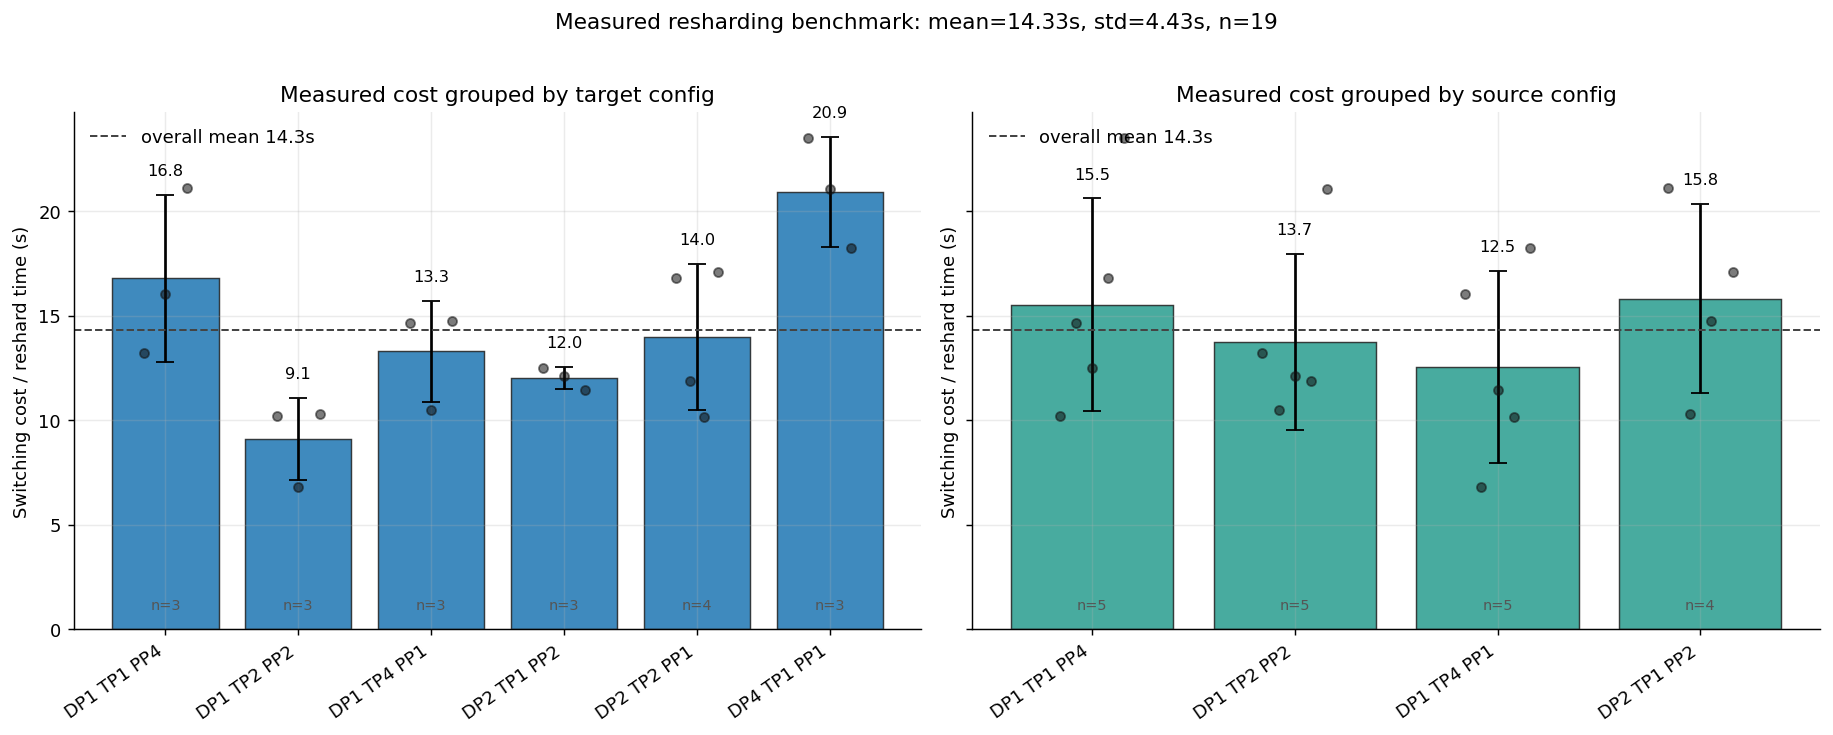

In [7]:
def plot_grouped_switching_cost(ax, stats, title, color):
    x = np.arange(len(stats))
    means = np.array([row["mean_s"] for row in stats])
    stds = np.array([row["std_s"] for row in stats])
    ax.bar(
        x,
        means,
        yerr=stds,
        capsize=5,
        color=color,
        edgecolor="#222222",
        linewidth=0.8,
        alpha=0.86,
    )
    ax.axhline(overall_mean, color="#444444", linestyle="--", linewidth=1.1, label=f"overall mean {overall_mean:.1f}s")
    for i, row in enumerate(stats):
        values = np.array(row["values"])
        jitter = np.linspace(-0.16, 0.16, len(values)) if len(values) > 1 else np.array([0.0])
        ax.scatter(i + jitter, values, s=25, color="#111111", alpha=0.55, zorder=3)
        ax.text(i, means[i] + stds[i] + 0.8, f"{means[i]:.1f}", ha="center", va="bottom", fontsize=9)
        ax.text(i, 0.8, f"n={row['n']}", ha="center", va="bottom", fontsize=8, color="#555555")
    ax.set_xticks(x)
    ax.set_xticklabels([row["label"] for row in stats], rotation=35, ha="right")
    ax.set_title(title)
    ax.set_ylabel("Switching cost / reshard time (s)")
    ax.legend(frameon=False, loc="upper left")

fig, axes = plt.subplots(1, 2, figsize=(14.2, 5.5), sharey=True)
plot_grouped_switching_cost(axes[0], by_target, "Measured cost grouped by target config", "#1f77b4")
plot_grouped_switching_cost(axes[1], by_source, "Measured cost grouped by source config", "#2a9d8f")
fig.suptitle(f"Measured resharding benchmark: mean={overall_mean:.2f}s, std={overall_std:.2f}s, n={len(all_switch_costs)}", y=1.02)
fig.tight_layout()
plt.show()